# Satellite paper — full run

**Runtime → Run all.** Allow Google Drive access when asked.

If the runtime restarts after installing packages, run **Runtime → Run all** once more.
Takes about 45–90 minutes. Keep this tab open. Results are saved in `MyDrive/Satellite_Full_Paper_Run/`.

In [3]:
# Connect Google Drive and find the program files
from google.colab import drive
drive.mount("/content/drive")
from pathlib import Path
CODE = Path("/content/drive/MyDrive/Satellite_Paper_Program")
missing = [f"step{i:02d}.py" for i in range(1, 15) if not (CODE / f"step{i:02d}.py").exists()]
assert not missing, f"Missing in Drive folder Satellite_Paper_Program: {missing}"


def run_step(n):
    path = CODE / f"step{n:02d}.py"
    exec(compile(path.read_text(encoding="utf-8"), str(path), "exec"), globals())


print("Program files found in", CODE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Program files found in /content/drive/MyDrive/Satellite_Paper_Program


In [4]:
# STEP 1 — Setup (packages, folders)
run_step(1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
            run_id: 20261108T181639Z
            python: 3.13.18
          platform: Linux-6.6.159+-x86_64-with-glibc2.39
               cpu: Intel(R) Xeon(R) CPU @ 2.20GHz
             numpy: 2.4.6
            pandas: 2.2.3
      scikit-learn: 1.6.1
        tensorflow: 2.20.0
             keras: 3.13.2
    ai-edge-litert: 2.3.0
         remotezip: 0.12.6
        matplotlib: 3.10.0
 inference_runtime: LiteRT 2.3.0
  intra_op_threads: 2
  inter_op_threads: 1
    op_determinism: True
               gpu: disabled

Outputs for this run: /content/drive/MyDrive/Satellite_Full_Paper_Run/runs/20261108T181639Z


In [5]:
# STEP 2 — Shared functions
run_step(2)

Functions ready.


In [6]:
# STEP 3 — OPS-SAT data
run_step(3)

✓ segments.csv verified (MD5 72f109630abb933a386106897a631188)
✓ dataset.csv verified (MD5 5246fdc5e4630a4cecbf7fb6bc8b795e)
✓ Segment integrity checks passed

Counts (✓ = same as the paper draft):
  ✓ Readings: 303,493
  ✓ Segments: 2,123
  ✓ Development fitting segments: 1,268
  ✓ Nominal fitting segments: 1,015
  ✓ Validation segments: 326
  ✓ Anomalous validation segments: 68
  ✓ Test segments (never scored here): 529
  ✓ Nominal fitting windows: 29,242
  ✓ Nominal validation windows: 8,385
  ✓ Validation windows: 12,135

Development windows kept: (55288, 8, 1) | test windows discarded


In [7]:
# STEP 4 — OPS-SAT controls
run_step(4)

  ✓ OPS-SAT representative INT8 inputs: 967
  ✓ Scored validation segments: 326
      model condition     f1  precision  recall
       PCA4        f1 0.8226     0.9107  0.7500
       PCA4       p99 0.7863     0.9388  0.6765
     ZScore        f1 0.3452     0.2086  1.0000
     ZScore       p99 0.0278     0.2500  0.0147
Persistence        f1 0.5532     0.5342  0.5735
Persistence       p99 0.4894     0.8846  0.3382


In [8]:
# STEP 5 — OPS-SAT training (6 runs)
run_step(5)


=== OPS-SAT | LSTM | seed 42 ===
  epochs 30 (best 30) | F1 FP32 0.7748 → INT8 0.6724 | files 58,876 / 76,176 bytes | median latency 29.0 / 27.2 µs | default-quantizer float tensors: 0

=== OPS-SAT | LSTM | seed 43 ===
  epochs 30 (best 29) | F1 FP32 0.8034 → INT8 0.7350 | files 58,876 / 76,176 bytes | median latency 47.2 / 46.5 µs | default-quantizer float tensors: 0

=== OPS-SAT | LSTM | seed 44 ===
  epochs 30 (best 30) | F1 FP32 0.8103 → INT8 0.7179 | files 58,876 / 76,336 bytes | median latency 29.0 / 28.1 µs | default-quantizer float tensors: 5

=== OPS-SAT | Dense | seed 42 ===
  epochs 30 (best 30) | F1 FP32 0.7869 → INT8 0.7788 | files 4,140 / 5,112 bytes | median latency 3.0 / 3.0 µs | default-quantizer float tensors: 0

=== OPS-SAT | Dense | seed 43 ===
  epochs 30 (best 30) | F1 FP32 0.8034 → INT8 0.8033 | files 4,140 / 5,112 bytes | median latency 3.1 / 3.0 µs | default-quantizer float tensors: 0

=== OPS-SAT | Dense | seed 44 ===
  epochs 30 (best 30) | F1 FP32 0.8244 → 

In [12]:
# STEP 6 — ESA download functions
run_step(6)

ESA download functions ready.


In [21]:
# STEP 7 — ESA download
run_step(7)

Using cached ESA files (SHA-256 re-verified).
Mode: HTTP range requests (selected members only) | 14 files verified


In [22]:
# STEP 8 — ESA blocks and labels
run_step(8)

labels.csv columns:        ['ID', 'Channel', 'StartTime', 'EndTime']
anomaly_types.csv columns: ['ID', 'Class', 'Subclass', 'Category', 'Dimensionality', 'Locality', 'Length']
Event categories (whole mission): {'Rare Event': 613, 'Anomaly': 31}
  channel_18:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 915
  channel_19:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 753
  channel_20:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 917
  channel_21:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 973
  channel_22:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 976
  channel_23:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 991
  channel_24:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 997
  channel_25:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 821
  channel_26:  5,814,779 raw readings in 2000-01 → 2002-10 | annotated blocks 827
  channel_27:  5,

In [15]:
# STEP 9 — ESA training + calibration + LOCK
run_step(9)

  ✓ ESA representative INT8 inputs: 967

=== ESA | LSTM | seed 42 ===
  epochs 30 (best 30) | calibration F1 FP32 0.3502 / INT8 0.3474 | files 58,876 / 75,976 bytes

=== ESA | LSTM | seed 43 ===
  epochs 30 (best 30) | calibration F1 FP32 0.3624 / INT8 0.3579 | files 58,876 / 75,976 bytes

=== ESA | LSTM | seed 44 ===
  epochs 30 (best 29) | calibration F1 FP32 0.3648 / INT8 0.3668 | files 58,876 / 76,336 bytes

=== ESA | Dense | seed 42 ===
  epochs 30 (best 30) | calibration F1 FP32 0.3610 / INT8 0.3610 | files 4,140 / 5,112 bytes

=== ESA | Dense | seed 43 ===
  epochs 30 (best 30) | calibration F1 FP32 0.3453 / INT8 0.3484 | files 4,140 / 5,112 bytes

=== ESA | Dense | seed 44 ===
  epochs 30 (best 30) | calibration F1 FP32 0.3571 / INT8 0.3571 | files 4,140 / 5,112 bytes

LOCKED: 30 files + evaluator code hashed. Lock SHA-256: 71a655d821af86f9c61066628959c20fb32a9a3e1078568c16c4e838a20d2aba
No confirmation block has been scored yet.


In [ ]:
# STEP 10 — ESA confirmation (scored once)
run_step(10)


Table 1 — Mean F1 ± sample SD over seeds (primary threshold rule)
            Cohort Model           FP32 F1           INT8 F1 Mean change SD of change
OPS-SAT validation  LSTM 0.7962 +/- 0.0189 0.7085 +/- 0.0324     -0.0877       0.0175
OPS-SAT validation Dense 0.8049 +/- 0.0188 0.8015 +/- 0.0220     -0.0034       0.0042
  ESA confirmation  LSTM 0.3249 +/- 0.0178 0.3309 +/- 0.0080     +0.0060       0.0144
  ESA confirmation Dense 0.3178 +/- 0.0217 0.3314 +/- 0.0234     +0.0137       0.0019

Table 2 — Every training seed (primary threshold rule)
            Cohort Model  Seed FP32 F1 INT8 F1  Change
OPS-SAT validation  LSTM    42  0.7748  0.6724 -0.1024
OPS-SAT validation  LSTM    43  0.8034  0.7350 -0.0684
OPS-SAT validation  LSTM    44  0.8103  0.7179 -0.0924
OPS-SAT validation Dense    42  0.7869  0.7788 -0.0081
OPS-SAT validation Dense    43  0.8034  0.8033 -0.0001
OPS-SAT validation Dense    44  0.8244  0.8226 -0.0018
  ESA confirmation  LSTM    42  0.3098  0.3219 +0.0121
  ESA c

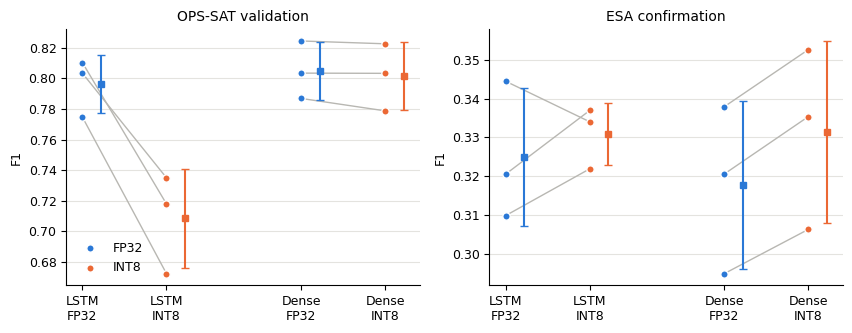

In [17]:
# STEP 11 — Tables and Fig. 1
run_step(11)

In [ ]:
# STEP 12 — Power estimate
run_step(12)

Confirmation year: 72,270 channel-blocks, 23,133,297 native readings
P0 (send everything): 46.27 MB per year for 11 channels

                       Flagged blocks  Block recall  Rare-event recall (by ID) True anomalies caught  P1 saving %  P2 saving %  False alarms in sent raw %
Detector                                                                                                                                                  
LSTM FP32                     672.667         0.196                      0.953       0/1 · 1/1 · 1/1       98.113       99.069                       4.498
LSTM INT8                     687.000         0.200                      0.955       1/1 · 1/1 · 1/1       98.093       99.050                       4.467
Dense FP32                    661.333         0.191                      0.945       1/1 · 0/1 · 1/1       98.128       99.085                       5.007
Dense INT8                    693.667         0.201                      0.948       1/1 · 0/1 · 1/

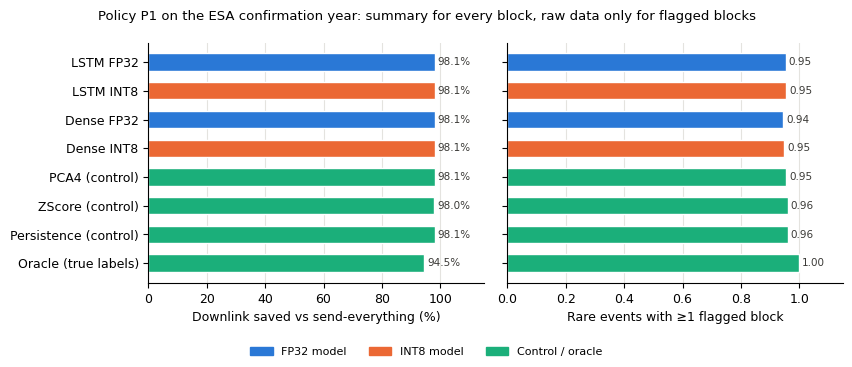

In [19]:
# STEP 13 — Downlink cost + Fig. 2
run_step(13)

In [20]:
# STEP 14 — Save everything + ZIP
run_step(14)

# Results for run 20261108T181639Z

Environment: Python 3.13.18, TensorFlow 2.20.0, LiteRT 2.3.0, CPU: Intel(R) Xeon(R) CPU @ 2.20GHz

All numbers below come from this run and replace the numbers in the current draft.


Saved /content/satellite_paper_run_20261108T181639Z.zip (19.0 MB). Drive copy: /content/drive/MyDrive/Satellite_Full_Paper_Run/runs/20261108T181639Z


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>